In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("listings.csv.gz")
print(df.shape)

FileNotFoundError: [Errno 2] No such file or directory: 'listings.csv.gz'

In [2]:
import os
print(os.getcwd())
print(os.listdir())

C:\Users\yassi\intro to ai code
['.ipynb_checkpoints', '01_cleaning.ipynb', 'listings (3).csv.gz']


In [4]:
import pandas as pd
import numpy as np

df = pd.read_csv("listings.csv.gz")
print(df.shape)

C:\Users\yassi\AppData\Local\Temp\ipykernel_12468\130826028.py:4: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("listings.csv.gz")


(91954, 90)


In [5]:
missing = df.isna().mean().sort_values(ascending=False)
print(missing.head(30))

neighbourhood                   1.000000
instant_bookable                1.000000
host_response_rate              1.000000
bathrooms                       1.000000
host_acceptance_rate            1.000000
host_since                      1.000000
host_thumbnail_url              1.000000
host_neighbourhood              1.000000
license                         1.000000
host_total_listings_count       1.000000
host_verifications              1.000000
neighborhood_overview           1.000000
neighbourhood_group_cleansed    1.000000
calendar_updated                1.000000
host_response_time              1.000000
source                          0.648618
host_about                      0.464308
price_quote_total_price         0.350099
price_quote_price_per_night     0.350099
estimated_revenue_l365d         0.348533
price                           0.348533
price_quote_checkin_date        0.317822
price_quote_checkout_date       0.317822
price_quote_raw                 0.317822
host_location   

In [6]:
# find columns where every value is missing
empty_cols = df.columns[df.isna().all()].tolist()
print(len(empty_cols), empty_cols)

# drop them (keep the original df untouched by making a copy)
df_clean = df.drop(columns=empty_cols)
print(df_clean.shape)

15 ['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'neighbourhood_group_cleansed', 'bathrooms', 'calendar_updated', 'license', 'instant_bookable']
(91954, 75)


In [7]:
drop_cols = [
    "id", "listing_url", "scrape_id", "host_id", "host_url",
    "host_profile_id", "host_profile_url", "picture_url", "host_picture_url",
    "name", "description", "host_name", "host_about", "host_location",
    "last_scraped", "calendar_last_scraped", "source",
    "price_quote_total_price", "price_quote_price_per_night",
    "price_quote_raw", "price_quote_checkin_date",
    "price_quote_checkout_date", "estimated_revenue_l365d",
]

df_clean = df_clean.drop(columns=drop_cols)
print(df_clean.shape)
print(df_clean.columns.tolist())

(91954, 52)
['hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_is_superhost', 'host_listings_count', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'has_availability', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy', 'number_of_reviews_ly', 'estimated_occupancy_l365d', 'first_review', 'last_review', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_locatio

In [8]:
print(df_clean["price"].head())

# strip $ and commas, then convert to a number
df_clean["price"] = (
    df_clean["price"].astype(str).str.replace("[$,]", "", regex=True)
)
df_clean["price"] = pd.to_numeric(df_clean["price"], errors="coerce")

n_before = len(df_clean)
df_clean = df_clean.dropna(subset=["price"])
print("rows before:", n_before)
print("rows after:", len(df_clean))
print("removed:", n_before - len(df_clean))
print(df_clean["price"].describe())

0    $267.50
1    $127.00
2    $137.50
3    $228.00
4        NaN
Name: price, dtype: object
rows before: 91954
rows after: 59905
removed: 32049
count    59905.000000
mean       248.354667
std        577.024272
min         10.000000
25%         99.670000
50%        175.000000
75%        279.750000
max      75000.000000
Name: price, dtype: float64


0.010      37.000
0.050      51.430
0.250      99.670
0.500     175.000
0.750     279.750
0.950     604.986
0.990    1272.160
0.999    6253.840
Name: price, dtype: float64
listings above $1000: 982
listings above $2000: 270
listings above $5000: 89


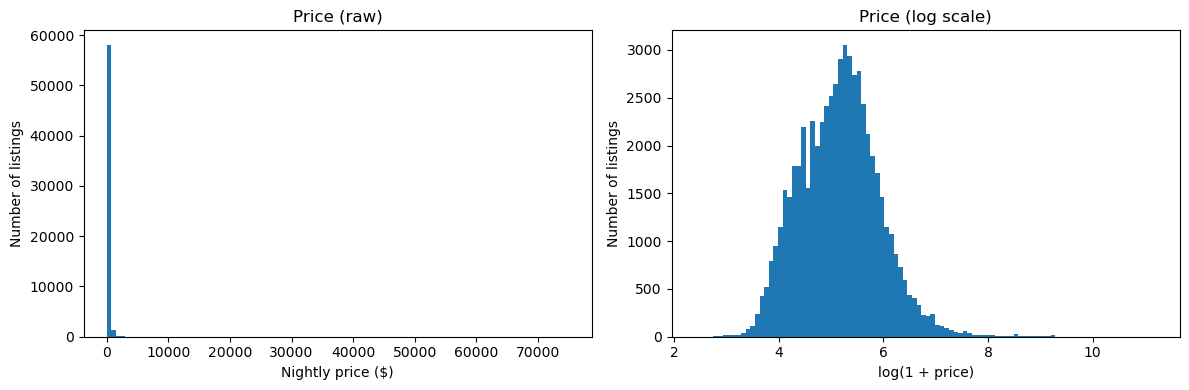

In [9]:
import matplotlib.pyplot as plt

print(df_clean["price"].quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]))
for limit in [1000, 2000, 5000]:
    print(f"listings above ${limit}:", (df_clean["price"] > limit).sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_clean["price"], bins=100)
axes[0].set_title("Price (raw)")
axes[0].set_xlabel("Nightly price ($)")
axes[0].set_ylabel("Number of listings")

axes[1].hist(np.log1p(df_clean["price"]), bins=100)
axes[1].set_title("Price (log scale)")
axes[1].set_xlabel("log(1 + price)")
axes[1].set_ylabel("Number of listings")
plt.tight_layout()
plt.show()

In [10]:
n_before = len(df_clean)
df_clean = df_clean[(df_clean["price"] >= 20) & (df_clean["price"] <= 1000)]
print("rows before:", n_before)
print("rows after:", len(df_clean))
print("removed:", n_before - len(df_clean))
print(df_clean["price"].describe())

rows before: 59905
rows after: 58895
removed: 1010
count    58895.000000
mean       213.076964
std        159.472732
min         20.000000
25%         99.000000
50%        172.000000
75%        272.000000
max       1000.000000
Name: price, dtype: float64


In [11]:
missing = df_clean.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(pd.DataFrame({"missing": missing, "share": (missing / len(df_clean)).round(3)}))

                             missing  share
review_scores_location         11765  0.200
review_scores_value            11764  0.200
review_scores_communication    11764  0.200
review_scores_checkin          11763  0.200
review_scores_cleanliness      11763  0.200
review_scores_accuracy         11763  0.200
first_review                   11760  0.200
last_review                    11760  0.200
review_scores_rating           11760  0.200
reviews_per_month              11760  0.200
beds                            1486  0.025
maximum_maximum_nights           298  0.005
minimum_maximum_nights           298  0.005
maximum_minimum_nights           298  0.005
minimum_minimum_nights           298  0.005
maximum_nights                   298  0.005
minimum_nights                   298  0.005
bathrooms_text                    87  0.001
bedrooms                          23  0.000
has_availability                   2  0.000


In [12]:
# check the missing review scores really are the listings with no reviews
no_reviews = (df_clean["number_of_reviews"] == 0)
print("listings with 0 reviews:", no_reviews.sum())
print("missing review_scores_rating:", df_clean["review_scores_rating"].isna().sum())

# flag for "has any reviews"
df_clean["has_reviews"] = (df_clean["number_of_reviews"] > 0).astype(int)

# no reviews means 0 reviews per month (not unknown)
df_clean["reviews_per_month"] = df_clean["reviews_per_month"].fillna(0)

# drop the date columns (raw dates aren't usable by the models as they are)
df_clean = df_clean.drop(columns=["first_review", "last_review"])
print(df_clean.shape)

listings with 0 reviews: 11760
missing review_scores_rating: 11760
(58895, 51)


In [13]:
df_clean.to_csv("listings_clean.csv", index=False)
print("saved", df_clean.shape)

saved (58895, 51)
